# Clasificación de cobertura de suelo con datos de Sentinel-2

**Geocomputación (1GEO20)** — PUCP, 2026-II — Semana 12

En este notebook se clasifica la cobertura de suelo de una zona de la Amazonía peruana a partir de seis bandas de Sentinel-2, usando como referencia el mapa de MapBiomas Perú. Se arma una tabla de píxeles, se entrenan un árbol de decisión y un Random Forest, se evalúan con una partición por zonas y se genera un mapa de toda la imagen. El flujo se controla desde la celda de parámetros y usa funciones de `utils_clasificacion.py`, que se reutilizan en la práctica.

## Bandas utilizadas

Las seis bandas provienen de Sentinel-2 (nivel L2A, reflectancia de superficie). Las longitudes de onda son aproximadas.

| Banda | Región del espectro | Longitud de onda (µm) | Resolución original |
|---|---|---|---|
| B02 | Azul | 0.49 | 10 m |
| B03 | Verde | 0.56 | 10 m |
| B04 | Rojo | 0.66 | 10 m |
| B08 | Infrarrojo cercano (NIR) | 0.83 | 10 m |
| B11 | Infrarrojo de onda corta (SWIR 1) | 1.61 | 20 m |
| B12 | Infrarrojo de onda corta (SWIR 2) | 2.19 | 20 m |

Para esta práctica, todas las bandas se llevaron a la grilla de 30 m de MapBiomas.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import ListedColormap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

import utils_clasificacion as uc

## Parámetros

In [2]:
AOI = "puerto_maldonado"
ANIO = 2025
CARPETA = "data/datos_clasificacion/"

# Agrupación de las clases de MapBiomas (nombre de la clase: códigos originales)
AGRUPACION = {
    "Bosque": [3],
    "Bosque inundable": [6],
    "Pasto, agropecuario y herbazal": [15, 21, 51],
    "Suelo sin vegetación": [23, 25],
    "Urbano": [24],
    "Minería": [30],
    "Agua": [33],
}

MUESTRAS_POR_CLASE = 1500   # máximo de píxeles por clase en la muestra
MIN_PIXELES = 2000          # una clase con menos píxeles en la imagen se descarta
PROP_PRUEBA = 0.2           # proporción de la muestra (o de bloques) para prueba
TAM_BLOQUE = 100            # lado del bloque, en píxeles (1 píxel = 30 m)
MODELO = "rf"               # modelo para evaluar y mapear: "rf" o "arbol"
SEMILLA = 42
GUARDAR_FIGURAS = True      # guarda las figuras en la carpeta figuras/

## Datos

La imagen tiene seis bandas de Sentinel-2 en reflectancia, alineadas a la grilla de MapBiomas. Los píxeles con nubes o sombras están como NaN.

In [3]:
with rasterio.open(CARPETA + f"s2_bandas_{ANIO}_{AOI}.tif") as src:
    pila = src.read()                      # forma (bandas, alto, ancho)
    bandas = list(src.descriptions)
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

with rasterio.open(CARPETA + f"mapbiomas_col4_{ANIO}_{AOI}.tif") as src:
    mapbiomas = src.read(1)

print("Imagen:", pila.shape, bandas)
print("MapBiomas:", mapbiomas.shape)

Imagen: (6, 743, 744) ['B02', 'B03', 'B04', 'B08', 'B11', 'B12']
MapBiomas: (743, 744)


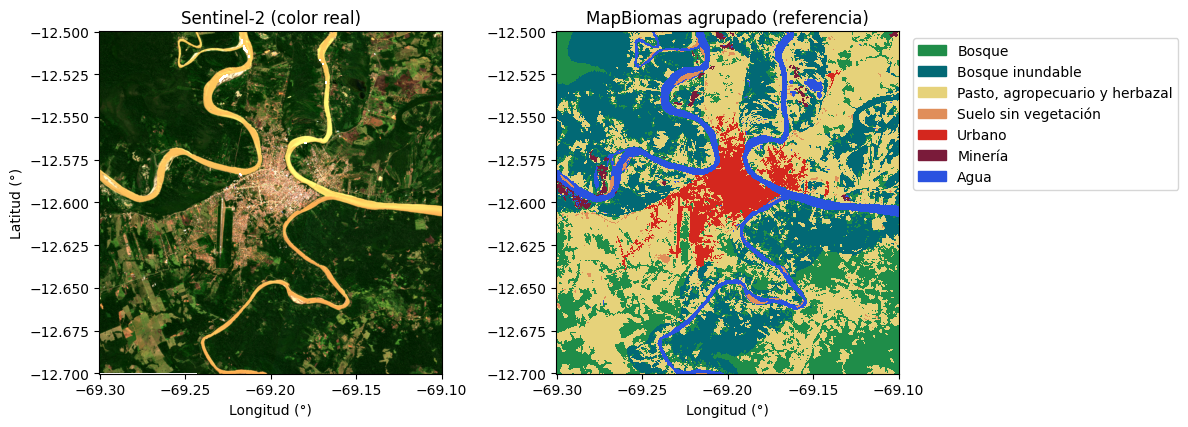

In [ ]:
grupos, nombres = uc.agrupar_clases(mapbiomas, AGRUPACION)
colores = uc.colores_para(nombres)

# Composición en color real (B04, B03, B02)
rgb = np.moveaxis(pila[[bandas.index(b) for b in ("B04", "B03", "B02")]], 0, -1)
p2, p98 = np.nanpercentile(rgb, (2, 98))
rgb = np.clip((rgb - p2) / (p98 - p2), 0, 1)

fig, ejes = plt.subplots(1, 2, figsize=(12, 5.5))
ejes[0].imshow(rgb, extent=extent)
ejes[0].set_title("Sentinel-2 (color real)")
ejes[1].imshow(np.ma.masked_equal(grupos, 0), cmap=ListedColormap(colores),
               vmin=0.5, vmax=len(nombres) + 0.5, extent=extent, interpolation="nearest")
ejes[1].set_title("MapBiomas agrupado (referencia)")
uc.leyenda_clases(ejes[1], nombres, colores, loc="upper left", bbox_to_anchor=(1.02, 1))
for ax in ejes:
    ax.set_xlabel("Longitud (°)")
ejes[0].set_ylabel("Latitud (°)")
plt.tight_layout()
uc.guardar_figura(fig, "01_imagen_y_referencia", GUARDAR_FIGURAS)
plt.show()

## Del ráster a la tabla

Cada píxel pasa a ser una fila de la tabla, con una columna por banda. La clase de cada píxel sale del mapa de referencia. Se excluyen los píxeles sin datos y los que no pertenecen a ninguna clase.

In [5]:
n_bandas, alto, ancho = pila.shape

X_todo = pila.reshape(n_bandas, -1).T          # una fila por píxel, una columna por banda
y_todo = grupos.ravel()                         # clase de cada píxel (0 = sin clase)
filas, columnas = np.divmod(np.arange(alto * ancho), ancho)   # posición de cada píxel

valido = ~np.isnan(X_todo).any(axis=1) & (y_todo > 0)
X_todo, y_todo = X_todo[valido], y_todo[valido]
filas, columnas = filas[valido], columnas[valido]

print(f"Imagen: {alto} x {ancho} = {alto * ancho} píxeles")
print(f"Tabla:  {X_todo.shape[0]} filas x {X_todo.shape[1]} columnas")

ejemplo = np.random.default_rng(SEMILLA).choice(len(y_todo), size=6, replace=False)
tabla = pd.DataFrame(X_todo[ejemplo], columns=bandas).round(3)
tabla["clase"] = [nombres[k - 1] for k in y_todo[ejemplo]]
tabla

Imagen: 743 x 744 = 552792 píxeles
Tabla:  552218 filas x 6 columnas


,B02,B03,B04,B08,B11,B12,clase
0,0.026,0.050,0.033,0.338,0.218,0.107,"Pasto, agropecuario y herbazal"
1,0.023,0.044,0.026,0.289,0.150,0.062,Bosque
2,0.025,0.056,0.027,0.360,0.208,0.093,"Pasto, agropecuario y herbazal"
3,0.020,0.036,0.022,0.249,0.160,0.070,Bosque
4,0.023,0.044,0.025,0.284,0.154,0.068,Bosque inundable
5,0.018,0.035,0.021,0.245,0.121,0.052,Bosque inundable


## Muestra de entrenamiento y prueba

Se toma una muestra con el mismo máximo de píxeles por clase, para que las clases poco frecuentes tengan ejemplos suficientes. Las clases con muy pocos píxeles en la imagen se descartan.

Como cada clase aporta un número parecido de muestras, la exactitud global que se calcula más adelante no equivale al porcentaje del área bien clasificada.

In [6]:
idx, clases = uc.muestrear_por_clase(y_todo, MUESTRAS_POR_CLASE, MIN_PIXELES, SEMILLA, nombres)
X, y = X_todo[idx], y_todo[idx]
f, c = filas[idx], columnas[idx]
nombres_clases = [nombres[k - 1] for k in clases]

pd.Series([nombres[k - 1] for k in y]).value_counts().rename("píxeles en la muestra").to_frame()

,píxeles en la muestra
Bosque inundable,1500
"Pasto, agropecuario y herbazal",1500
Bosque,1500
Minería,1500
Suelo sin vegetación,1500
Agua,1500
Urbano,1500


## Partición

Se comparan dos formas de separar entrenamiento y prueba. En la partición aleatoria, un píxel de prueba suele tener vecinos casi idénticos en el entrenamiento. En la partición por bloques, zonas completas quedan reservadas para la prueba.

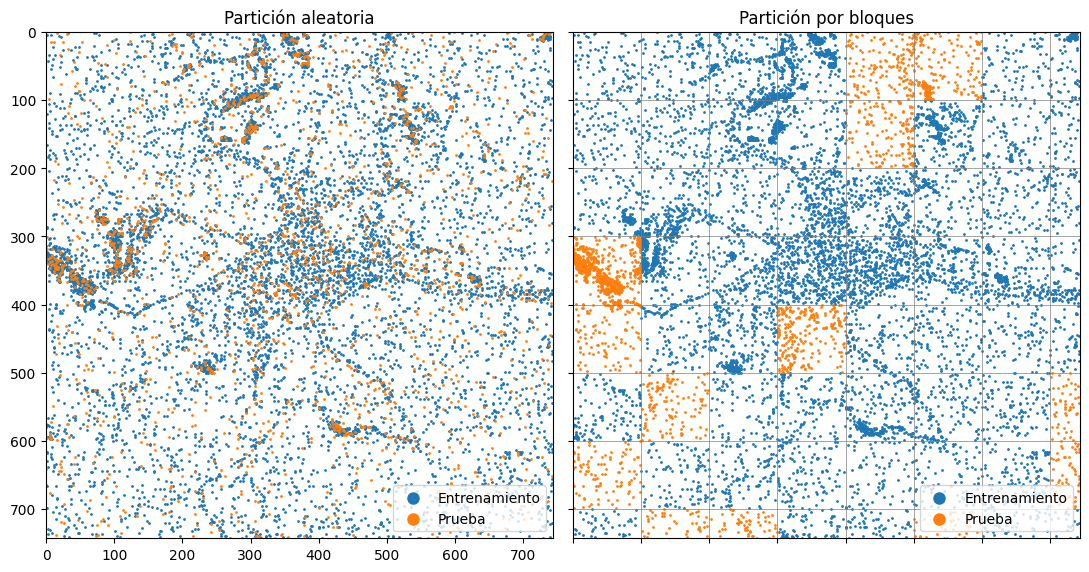

In [ ]:
# Partición aleatoria
idx_ent, idx_pru = train_test_split(np.arange(len(y)), test_size=PROP_PRUEBA, random_state=SEMILLA)
es_prueba_azar = np.zeros(len(y), dtype=bool)
es_prueba_azar[idx_pru] = True

# Partición por bloques
es_prueba_bloques = uc.dividir_por_bloques(f, c, TAM_BLOQUE, PROP_PRUEBA, SEMILLA, y=y)

fig, ejes = plt.subplots(1, 2, figsize=(11, 5.5))
uc.mapa_particion(f, c, es_prueba_azar, (alto, ancho), ejes[0], "Partición aleatoria")
uc.mapa_particion(f, c, es_prueba_bloques, (alto, ancho), ejes[1], "Partición por bloques", tam_bloque=TAM_BLOQUE)
plt.tight_layout()
uc.guardar_figura(fig, "02_particion", GUARDAR_FIGURAS)
plt.show()

## Entrenamiento

Se entrenan un árbol de decisión sin límite de profundidad y un Random Forest, con la partición por bloques. La comparación entre la exactitud en entrenamiento y en prueba muestra cuánto sobreajusta cada uno.

In [8]:
X_ent, X_pru = X[~es_prueba_bloques], X[es_prueba_bloques]
y_ent, y_pru = y[~es_prueba_bloques], y[es_prueba_bloques]
print(f"Entrenamiento: {len(y_ent)} píxeles   Prueba: {len(y_pru)} píxeles")

arbol = DecisionTreeClassifier(random_state=SEMILLA).fit(X_ent, y_ent)     # sin límite de profundidad
bosque = RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1).fit(X_ent, y_ent)

for nombre, m in [("Árbol de decisión", arbol), ("Random Forest", bosque)]:
    print(f"{nombre:18s} entrenamiento {m.score(X_ent, y_ent):.3f}   prueba {m.score(X_pru, y_pru):.3f}")
print("Profundidad del árbol:", arbol.get_depth())

Entrenamiento: 8480 píxeles   Prueba: 2020 píxeles
Árbol de decisión  entrenamiento 1.000   prueba 0.595
Random Forest      entrenamiento 1.000   prueba 0.665
Profundidad del árbol: 24


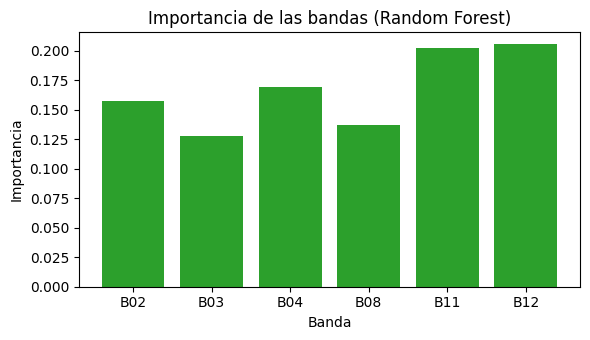

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(bandas, bosque.feature_importances_, color="tab:green")
ax.set_xlabel("Banda")
ax.set_ylabel("Importancia")
ax.set_title("Importancia de las bandas (Random Forest)")
plt.tight_layout()
uc.guardar_figura(fig, "03_importancia_bandas", GUARDAR_FIGURAS)
plt.show()

## Evaluación

La matriz de confusión compara la clase de referencia (filas) con la clase predicha (columnas), usando solo los datos de prueba. El modelo evaluado depende del parámetro `MODELO`.

Exactitud global en prueba: 0.665

                                Exactitud del usuario  \
Bosque                                          0.758   
Bosque inundable                                0.513   
Pasto, agropecuario y herbazal                  0.767   
Suelo sin vegetación                            0.424   
Urbano                                          0.562   
Minería                                         0.776   
Agua                                            0.723   

                                Exactitud del productor  Píxeles de prueba  
Bosque                                            0.550                353  
Bosque inundable                                  0.828                186  
Pasto, agropecuario y herbazal                    0.712                337  
Suelo sin vegetación                              0.485                200  
Urbano                                            0.669                169  
Minería                                       

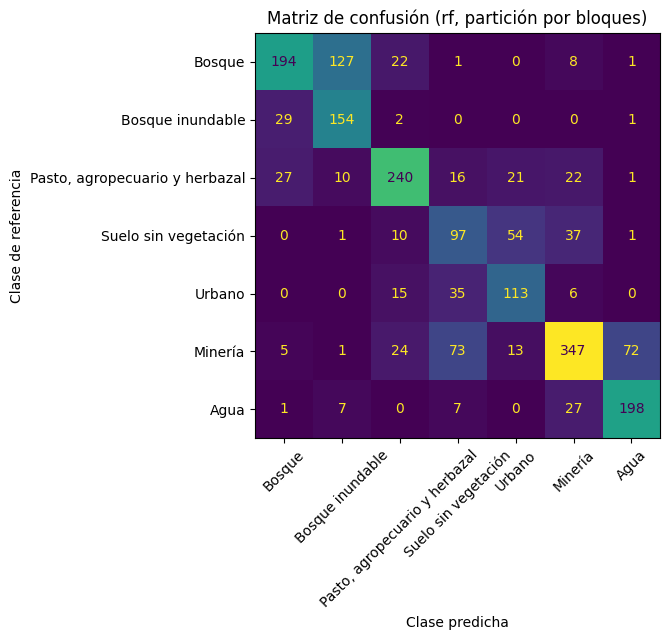

In [ ]:
modelo = {"arbol": arbol, "rf": bosque}[MODELO]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
uc.evaluar(modelo, X_pru, y_pru, clases, nombres_clases, ax=ax,
           titulo=f"Matriz de confusión ({MODELO}, partición por bloques)")
plt.tight_layout()
uc.guardar_figura(fig, "04_matriz_confusion_{MODELO}", GUARDAR_FIGURAS)
plt.show()

In [11]:
# Mismo modelo, entrenado con la partición aleatoria
bosque_azar = RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1)
bosque_azar.fit(X[~es_prueba_azar], y[~es_prueba_azar])

print(f"Random Forest, exactitud en prueba con partición aleatoria:   {bosque_azar.score(X[es_prueba_azar], y[es_prueba_azar]):.3f}")
print(f"Random Forest, exactitud en prueba con partición por bloques: {bosque.score(X_pru, y_pru):.3f}")

Random Forest, exactitud en prueba con partición aleatoria:   0.707
Random Forest, exactitud en prueba con partición por bloques: 0.665


## Predicción sobre toda la imagen

El modelo clasifica todos los píxeles con datos y el resultado se reordena con la forma de la imagen. Los píxeles sin datos quedan en blanco.

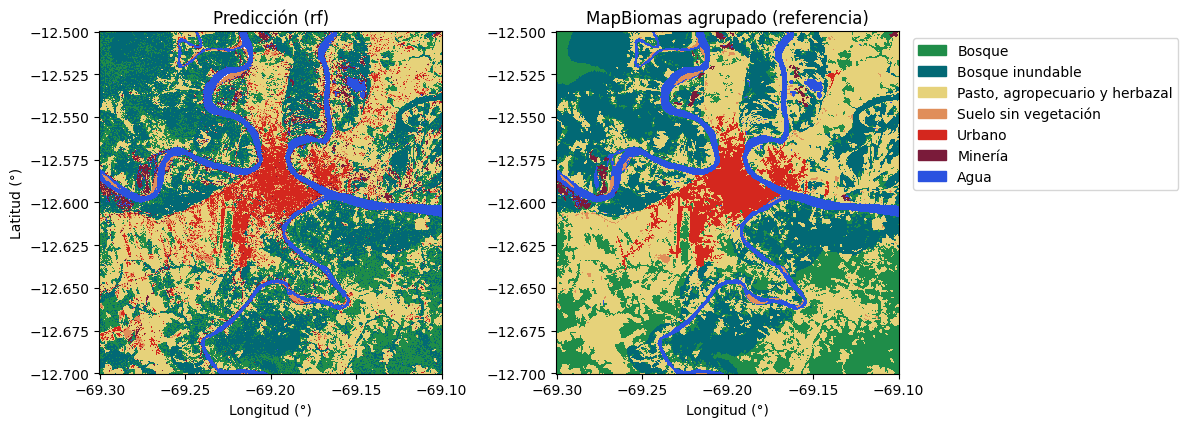

In [ ]:
mapa_pred = uc.predecir_imagen(modelo, pila)

# Referencia con las mismas clases que el modelo (sin las clases descartadas)
referencia = np.where(np.isin(grupos, clases), grupos, 0)

fig, ejes = plt.subplots(1, 2, figsize=(12, 5.5))
opciones = dict(cmap=ListedColormap(colores), vmin=0.5, vmax=len(nombres) + 0.5, extent=extent, interpolation="nearest")
ejes[0].imshow(np.ma.masked_invalid(np.where(mapa_pred > 0, mapa_pred, np.nan)), **opciones)
ejes[0].set_title(f"Predicción ({MODELO})")
ejes[1].imshow(np.ma.masked_equal(referencia, 0), **opciones)
ejes[1].set_title("MapBiomas agrupado (referencia)")
uc.leyenda_clases(ejes[1], nombres_clases, [colores[k - 1] for k in clases], loc="upper left", bbox_to_anchor=(1.02, 1))
for ax in ejes:
    ax.set_xlabel("Longitud (°)")
ejes[0].set_ylabel("Latitud (°)")
plt.tight_layout()
uc.guardar_figura(fig, "05_prediccion_{MODELO}_vs_referencia", GUARDAR_FIGURAS)
plt.show()

## Ejercicios

En esta sección se modifican decisiones del flujo y se compara el resultado con la línea base, que corresponde al Random Forest entrenado con la partición por bloques.

### Ejercicio 1. Variables derivadas

A partir de las bandas de la imagen se construyen dos variables adicionales que podrían ser útiles para separar las clases de esta zona, y se agregan a la tabla de píxeles.

- **NDVI** = (B08 - B04) / (B08 + B04): índice de vegetación (infrarrojo cercano y rojo). Valores altos indican vegetación densa.
- **MNDWI** = (B03 - B11) / (B03 + B11): índice de agua modificado (verde e infrarrojo de onda corta). Valores altos suelen indicar agua.

Se reentrena el modelo con las mismas muestras y la misma partición por bloques de la línea base, y se compara la exactitud global y por clase con las de la línea base. A partir de la matriz de confusión se identifica qué clases mejoran o empeoran y por qué podría ocurrir. Se verifica además que las nuevas variables no introduzcan valores no válidos.

Valores no válidos en la tabla: 0
Exactitud global en prueba: 0.660

                                Exactitud del usuario  \
Bosque                                          0.767   
Bosque inundable                                0.514   
Pasto, agropecuario y herbazal                  0.753   
Suelo sin vegetación                            0.406   
Urbano                                          0.544   
Minería                                         0.777   
Agua                                            0.713   

                                Exactitud del productor  Píxeles de prueba  
Bosque                                            0.569                353  
Bosque inundable                                  0.817                186  
Pasto, agropecuario y herbazal                    0.706                337  
Suelo sin vegetación                              0.455                200  
Urbano                                            0.657                169  
Minería     

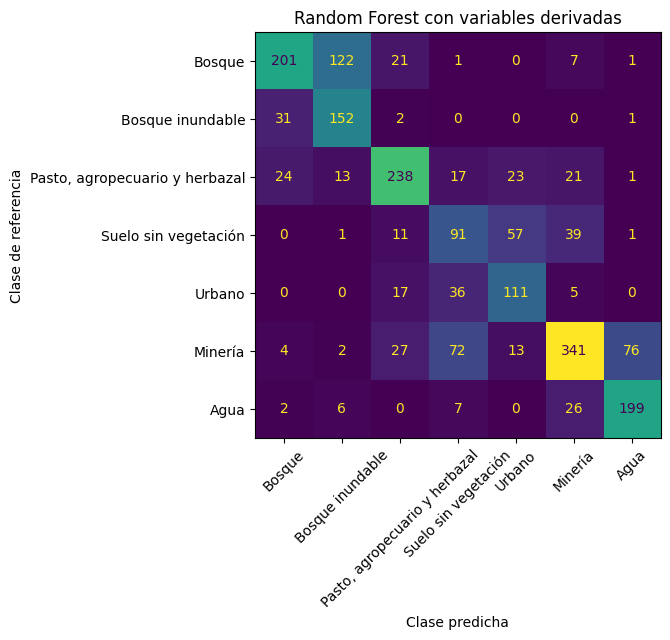

Línea base: 0.665   con variables derivadas: 0.660


In [13]:
b = {nombre: pila[i] for i, nombre in enumerate(bandas)}

# Si el denominador es 0 (reflectancia 0 en ambas bandas), la división da NaN o infinito
# y NumPy emite una advertencia. np.errstate silencia esas advertencias solo dentro del
# bloque "with". 
with np.errstate(divide="ignore", invalid="ignore"):
    ndvi = (b["B08"] - b["B04"]) / (b["B08"] + b["B04"])
    mndwi = (b["B03"] - b["B11"]) / (b["B03"] + b["B11"])

pila_ext = np.concatenate([pila, np.stack([ndvi, mndwi])])         # (8, alto, ancho)
X_ext = pila_ext.reshape(pila_ext.shape[0], -1).T[valido][idx]     # mismas muestras que la línea base
print("Valores no válidos en la tabla:", (~np.isfinite(X_ext)).sum())
X_ext = np.nan_to_num(X_ext, nan=0.0, posinf=0.0, neginf=0.0)      # reemplazo simple por 0

exactitud_base = bosque.score(X_pru, y_pru)
bosque_ext = RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1)
bosque_ext.fit(X_ext[~es_prueba_bloques], y_ent)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
exactitud_ext = uc.evaluar(bosque_ext, X_ext[es_prueba_bloques], y_pru, clases,
                           nombres_clases, ax=ax, titulo="Random Forest con variables derivadas")
plt.tight_layout()
plt.show()
print(f"Línea base: {exactitud_base:.3f}   con variables derivadas: {exactitud_ext:.3f}")

### Ejercicio 2. Complejidad y sobreajuste

Se estudia cómo cambian la exactitud en entrenamiento y en prueba al variar la profundidad máxima de los árboles del Random Forest, con la misma partición de la línea base. El resultado se presenta en una figura, y a partir de ella se propone un valor de profundidad y se justifica la elección.

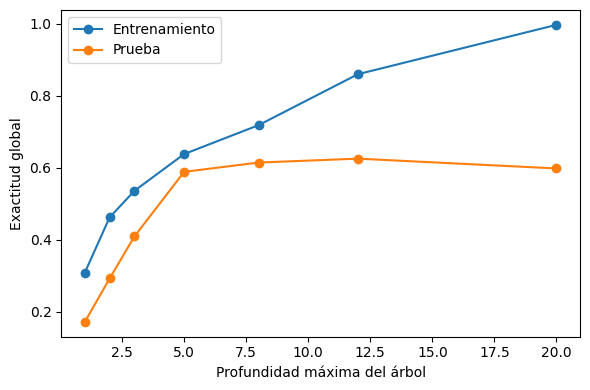

,profundidad,entrenamiento,prueba
0,1,0.309,0.172
1,2,0.462,0.293
2,3,0.536,0.409
3,5,0.638,0.589
4,8,0.718,0.614
5,12,0.860,0.625
6,20,0.997,0.598


In [14]:
# Efecto de la profundidad máxima en un árbol de decisión
profundidades = [1, 2, 3, 5, 8, 12, 20]
resultados = []
for d in profundidades:
    m = DecisionTreeClassifier(max_depth=d, random_state=SEMILLA).fit(X_ent, y_ent)
    resultados.append({"profundidad": d, "entrenamiento": m.score(X_ent, y_ent), "prueba": m.score(X_pru, y_pru)})
resultados = pd.DataFrame(resultados)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(resultados["profundidad"], resultados["entrenamiento"], marker="o", label="Entrenamiento")
ax.plot(resultados["profundidad"], resultados["prueba"], marker="o", label="Prueba")
ax.set_xlabel("Profundidad máxima del árbol")
ax.set_ylabel("Exactitud global")
ax.legend()
plt.tight_layout()
plt.show()
resultados.round(3)

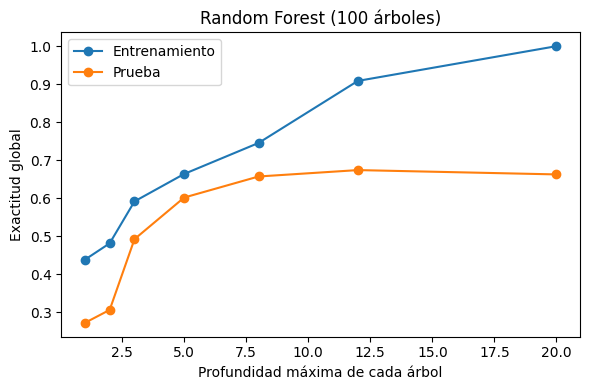

,profundidad,entrenamiento,prueba
0,1,0.438,0.272
1,2,0.481,0.306
2,3,0.591,0.492
3,5,0.664,0.601
4,8,0.745,0.657
5,12,0.908,0.674
6,20,1.000,0.662


In [15]:
# Efecto de la profundidad máxima de cada árbol en un Random Forest
profundidades = [1, 2, 3, 5, 8, 12, 20]
resultados = []
for d in profundidades:
    m = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=SEMILLA, n_jobs=-1)
    m.fit(X_ent, y_ent)
    resultados.append({"profundidad": d,
                       "entrenamiento": m.score(X_ent, y_ent),
                       "prueba": m.score(X_pru, y_pru)})
resultados = pd.DataFrame(resultados)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(resultados["profundidad"], resultados["entrenamiento"], marker="o", label="Entrenamiento")
ax.plot(resultados["profundidad"], resultados["prueba"], marker="o", label="Prueba")
ax.set_xlabel("Profundidad máxima de cada árbol")
ax.set_ylabel("Exactitud global")
ax.set_title("Random Forest (100 árboles)")
ax.legend()
plt.tight_layout()
plt.show()
resultados.round(3)

### Ejercicio 3. Partición y variabilidad

Se evalúa cuánto depende la exactitud en prueba de la forma de separar los datos. Se compara la partición aleatoria con la partición por bloques, repitiendo el experimento con distintas semillas (sirve cualquier número entero), y se resumen los resultados en una tabla con el promedio y la desviación estándar de cada partición.

Para esto se reúne el flujo (muestra, partición, entrenamiento y evaluación) en una función con docstring que reciba los parámetros que varían y devuelva la exactitud en prueba. Finalmente se discute qué cifra convendría reportar para estimar el desempeño del modelo en otra zona de la Amazonía.

Cada ____ es un hueco, y si se ejecuta sin completar da un NameError, así que el error se nota.

In [ ]:
def correr_experimento(particion, semilla, tam_bloque=TAM_BLOQUE):
    """
    Entrena un Random Forest con una muestra por clase y devuelve la exactitud en prueba.

    Parámetros
    ----------
    particion (str) : "bloques" o "aleatoria", forma de separar entrenamiento y prueba.
    semilla (int) : Semilla para la generación de números aleatorios.
    tam_bloque (int) : Tamaño del bloque para la partición por bloques.

    Devuelve
    --------
    COMPLETAR
    """
    # 1. Muestra por clase
    idx, _ = uc.muestrear_por_clase(y_todo, ____, ____, ____)
    X, y = X_todo[____], y_todo[____]

    # 2. Partición. es_prueba vale True para los píxeles de prueba y False para los de entrenamiento
    if particion == "bloques":
        es_prueba = uc.dividir_por_bloques(filas[idx], columnas[idx], ____, PROP_PRUEBA, ____, y=y)
    else:
        es_prueba = np.zeros(len(y), dtype=bool)
        indices_prueba = train_test_split(np.arange(len(y)), test_size=PROP_PRUEBA, random_state=____)[1]
        es_prueba[____] = True

    # 3. Modelo entrenado solo con los datos de entrenamiento
    modelo = RandomForestClassifier(n_estimators=100, random_state=____, n_jobs=-1)
    modelo.fit(X[____], y[____])

    # 4. Exactitud en prueba
    return modelo.score(X[____], y[____])

In [ ]:
resultados = []
for particion in ("aleatoria", "bloques"):
    for semilla in range(____):                       # número de semillas a probar
        exactitud = correr_experimento(____, ____)
        resultados.append({"particion": particion, "semilla": semilla, "exactitud": exactitud})

tabla = pd.DataFrame(resultados)
tabla.groupby("particion")["exactitud"].agg(["mean", "std"]).round(3)